# Circular LEN-word generator

Enter `LEN` as the number of bits in each word. For `LEN = 2`, the circular order is `11 → 00 → 01 → 10 → 11`. The code checks uniqueness, plots the circle, and saves the full sequence to CSV and TXT.

Enter LEN (number of bits per word, 1-16):  3


LEN = 3 bits
Distinct words on the circle = 8
The final word loops back to the first word.
111 -> 000 -> 001 -> 010 -> 011 -> 100 -> 101 -> 110


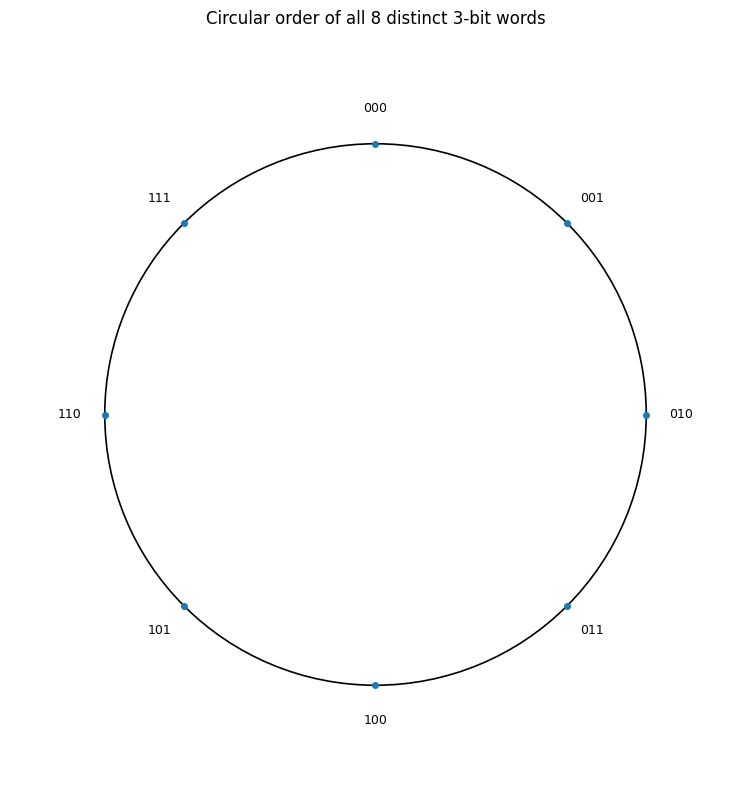


Saved complete outputs:
CSV: D:\@User Data\Downloads\circle_LEN_3.csv
TXT: D:\@User Data\Downloads\circle_LEN_3.txt
PNG: D:\@User Data\Downloads\circle_LEN_3.png
SVG: D:\@User Data\Downloads\circle_LEN_3.svg
Note: for larger LEN values, the plot labels are thinned for readability; the CSV and TXT contain the full cycle.


In [1]:
"""Generate every LEN-bit word exactly once in circular order.

For LEN=2, the order is: 11, 00, 01, 10 (then back to 11).
Run this file in Jupyter, or paste it into a notebook cell.
"""

import csv
import math
from pathlib import Path

import matplotlib.pyplot as plt

# LEN means the number of bits in each word. Examples: 2 -> 4 words; 8 -> 256 bytes.
LEN = int(input("Enter LEN (number of bits per word, 1-16): ").strip())
if not 1 <= LEN <= 16:
    raise ValueError("Choose LEN from 1 to 16. The number of words doubles with each added bit.")

COUNT = 1 << LEN

# Start at the all-ones word, wrap to all zeros, then count upward.
# This reproduces the requested LEN=2 cycle: 11 -> 00 -> 01 -> 10 -> (back to 11).
values = [COUNT - 1] + list(range(COUNT - 1))
words = [format(value, f"0{LEN}b") for value in values]

# Invariants: every fixed-width word appears once, and the cycle has COUNT entries.
assert len(words) == COUNT
assert len(set(words)) == COUNT
assert set(values) == set(range(COUNT))

print(f"LEN = {LEN} bits")
print(f"Distinct words on the circle = {COUNT:,}")
print("The final word loops back to the first word.")
if COUNT <= 64:
    print(" -> ".join(words))
else:
    print("Sequence preview:")
    print(" -> ".join(words[:16]) + " -> ... -> " + " -> ".join(words[-4:]))

# Save the complete order, so every word is available even when the circle is too dense to label.
out_dir = Path.cwd()
base = f"circle_LEN_{LEN}"
csv_path = out_dir / f"{base}.csv"
txt_path = out_dir / f"{base}.txt"
png_path = out_dir / f"{base}.png"
svg_path = out_dir / f"{base}.svg"
hex_width = math.ceil(LEN / 4)

with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["circle_position", "decimal_value", "binary_word", "hex_value"])
    for position, (value, word) in enumerate(zip(values, words)):
        writer.writerow([position, value, word, format(value, f"0{hex_width}X")])

with txt_path.open("w", encoding="utf-8") as f:
    f.write(" -> ".join(words) + " -> " + words[0] + "\n")

# Draw the circular arrangement. Position 0 (all ones) starts upper-left;
# the next word is clockwise, matching the supplied 2-bit example.
angles = [3 * math.pi / 4 - (2 * math.pi * i / COUNT) for i in range(COUNT)]
xs = [math.cos(angle) for angle in angles]
ys = [math.sin(angle) for angle in angles]

fig_size = 8 if LEN <= 5 else 10
fig, ax = plt.subplots(figsize=(fig_size, fig_size))
ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, linewidth=1.2))
ax.scatter(xs, ys, s=16 if COUNT <= 256 else 5, zorder=3)

# Label every location for small circles. For large circles, label a regular subset
# to keep the picture legible; the CSV/TXT still contain every distinct word.
if COUNT <= 64:
    label_step = 1
else:
    label_step = math.ceil(COUNT / 32)
label_indices = set(range(0, COUNT, label_step))
label_indices.update({0, 1, COUNT - 1})
font_size = 9 if LEN <= 3 else (7 if LEN <= 5 else 5)
for i in sorted(label_indices):
    radius = 1.13
    x = radius * xs[i]
    y = radius * ys[i]
    ax.text(x, y, words[i], ha="center", va="center", fontsize=font_size)

ax.set_title(f"Circular order of all {COUNT:,} distinct {LEN}-bit words", pad=18)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.35, 1.35)
ax.axis("off")
fig.tight_layout()
fig.savefig(png_path, dpi=220, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.show()

print("\nSaved complete outputs:")
print(f"CSV: {csv_path}")
print(f"TXT: {txt_path}")
print(f"PNG: {png_path}")
print(f"SVG: {svg_path}")
print("Note: for larger LEN values, the plot labels are thinned for readability; the CSV and TXT contain the full cycle.")
